# Credit-risk scorecard: the whole project, step by step

This notebook walks through every step of the project in order, on the real data, using the same code as the repository (`src/crs/`).
Each idea is explained in plain words first, then computed, and the important formulas are worked out by hand once
so you can see there is no magic.

**The question:** someone applies for a 36-month personal loan. Using only what we know at that moment, how likely are they to
default, should we lend, at what price, and why?

| Step | What happens | Section |
|---|---|---|
| 1 | Load and check 2.26 M Lending Club loans | Data |
| 2 | Decide who is in the model, what "default" means, and which columns are allowed | Target and leakage |
| 3 | Split by time: develop on 2007–2014, test once on 2015 | Validation design |
| 4 | Cut each characteristic into bins and measure how risky each bin is (WoE, IV) | Binning |
| 5 | Choose characteristics, fit a logistic regression, turn it into points | Scorecard |
| 6 | Give reasons for every decision | Reasons |
| 7 | Test on 2015, compare with Lending Club's own grade and a LightGBM challenger | Out-of-time test |
| 8 | Check whether the predicted default rates are right (calibration) | Calibration |
| 9 | Turn the score into money: approve or decline, and the investor view | Decisions |
| 10 | Who the model never saw: rejected applicants | Reject bias |
| 11 | Watch the model after go-live (PSI, early defaults) | Monitoring |
| 12 | Lending rules and scoring one application, as the API and the page do | Using it |

To run it yourself: `make install`, `make download`, `make data`, then open this notebook (`make notebook`).
Without the real data it falls back to synthetic loans, so every cell still runs, but the numbers differ.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from crs import (
    applicant,
    binning,
    challenger,
    config,
    features,
    monitor,
    policy,
    rejects,
    scorecard,
    strategy,
    target,
    validation,
)
from crs.data import fixture, load, quality

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

REAL = config.LOANS_PATH.exists()
loans = load.load() if REAL else load.clean(fixture.synthetic_raw(n=60000, seed=0))
print("real Lending Club data" if REAL else "synthetic loans (run make download and make data for the real ones)")
print(f"{len(loans):,} loans, issued {loans['issue_d'].min():%b %Y} to {loans['issue_d'].max():%b %Y}")

real Lending Club data
2,260,668 loans, issued Jun 2007 to Dec 2018


## 1. Data

Lending Club was a US marketplace lender, the same business model as auxmoney: people apply online, investors fund the loans.
The public file has one row per approved loan, with about 150 columns. We read the ones we need and turn text into numbers and
dates (`"36 months"` → 36, `"10+ years"` → 10, `"Dec-2015"` → a date). That happens in `crs.data.load.clean`.

A few rows of the columns that matter most:

In [2]:
show = ["issue_d", "term", "loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "inq_last_6mths",
        "purpose", "grade", "int_rate", "loan_status"]
loans[show].sample(5, random_state=1)

,issue_d,term,loan_amnt,annual_inc,dti,fico_range_low,revol_util,inq_last_6mths,purpose,grade,int_rate,loan_status
1832766,2018-02-01,36,"4,000.0000","60,000.0000",6.7800,700.0000,21.2000,0.0000,credit_card,A,6.7100,Current
1380734,2017-02-01,36,"5,500.0000","62,000.0000",19.1100,670.0000,67.4000,0.0000,other,C,15.9900,Current
560750,2015-04-01,36,"13,600.0000","48,000.0000",13.9800,720.0000,35.0000,2.0000,home_improvement,B,9.1700,Fully Paid
2156089,2018-10-01,36,"10,000.0000","50,000.0000",14.9100,715.0000,18.5000,1.0000,debt_consolidation,B,10.4700,Current
616767,2015-05-01,36,"12,000.0000","68,000.0000",12.8800,680.0000,45.0000,1.0000,credit_card,B,10.9900,Fully Paid


Before modelling, the data checks (`crs.data.quality`): no duplicate loans, every loan has an issue date and a known status,
terms are 36 or 60 months, amounts are positive, FICO ranges make sense, and nobody's first credit line is after their loan.

In [3]:
problems = quality.check(loans)
print("data checks:", "all passed" if not problems else problems)
quality.population(loans)

data checks: all passed


loan_status,Fully Paid,Charged Off,Default,Current,In Grace Period,Late (16-30 days),Late (31-120 days),total
issue year,,,,,,,,
2007,445,158,0,0,0,0,0,603
2008,1897,496,0,0,0,0,0,2393
2009,4558,723,0,0,0,0,0,5281
2010,10780,1757,0,0,0,0,0,12537
2011,18424,3297,0,0,0,0,0,21721
2012,44723,8644,0,0,0,0,0,53367
2013,113780,21024,0,6,1,0,3,134814
2014,181941,41161,1,11919,200,73,334,235629
2015,299742,75803,1,43299,612,279,1359,421095


The table already shows an important fact: loans issued in 2016–2018 are mostly still `Current` when the data ends,
so we do not know yet whether they will default. They cannot be used to train a default model, only to watch it later.

## 2. Target, population and leakage

**Population** (who the model is for): 36-month loans issued 2007–2015. A loan from December 2015 ends in December 2018,
when the data ends, so every loan in the population had its full term to default.

**Target** (what we predict): bad = `Charged Off` or `Default`, good = `Fully Paid`. Loans still open or late have no final
outcome and are left out.

In [4]:
print(target.exclusions(loans).to_string(), "\n")
pop = target.population(loans)
target.bad_rate_by_year(pop)

issued after 2015 (term not over): monitoring only    988585
60-month term                                         650914
in the population                                     621022
no final outcome (still open or late)                    147 



,loans,bad_rate
year,,
2007,603,0.2620
2008,2393,0.2073
2009,5281,0.1369
2010,9156,0.1092
2011,14101,0.1063
2012,43470,0.1358
2013,100422,0.1233
2014,162570,0.1373
2015,283026,0.1489


Defaults were very high in 2007–08 (financial crisis, young platform), lowest around 2010–11, and rising again until 2015.
Keep that last point in mind: it comes back in calibration and monitoring.

**Leakage** is the biggest trap in this dataset. About half the columns are only filled in *after* the loan was paid out:
how much was paid back, recoveries, the last payment date, the last FICO score. A model that uses them looks perfect and is
useless, because at application time those values do not exist yet.

So every column belongs to exactly one group (`crs.config`), and only the application-time group can reach a model.
Lending Club's own `grade` and `int_rate` are not inputs either: they are Lending Club's risk model, so they are the
**benchmark** we compare against.

In [5]:
pd.DataFrame({
    "group": ["application time (may be used)", "benchmark (compare only)", "outcome (never)", "not for models (fairness)"],
    "columns": [", ".join(config.APPLICATION), ", ".join(config.BENCHMARK), ", ".join(config.OUTCOME), ", ".join(config.NOT_FOR_MODELS)],
})

,group,columns
0,application time (may be used),"loan_amnt, emp_length, home_ownership, annual_..."
1,benchmark (compare only),"grade, sub_grade, int_rate, installment"
2,outcome (never),"loan_status, total_pymnt, total_rec_prncp, tot..."
3,not for models (fairness),addr_state


How badly does leakage fool you? Rank the 2015 loans by one post-loan column, the share of the principal that was repaid:

In [6]:
dev, oot = target.split(pop)
print(f"Gini using only 'share of principal repaid': {validation.leak_demo(oot):.3f}  (1.0 = perfect)")
print("A perfect-looking model that cannot be used on a single new application.")

Gini using only 'share of principal repaid': 1.000  (1.0 = perfect)
A perfect-looking model that cannot be used on a single new application.


The gate in `crs.features.build` builds the model inputs only from application-time columns, adds three derived ones
(middle of the FICO range, months of credit history, loan amount / income) and raises an error if anything else gets in.
A test in `tests/test_target_features.py` tries to sneak in payment columns, the grade and the state, and checks that it fails.

In [7]:
X_all = features.build(pop)
print(X_all.shape[1], "candidate characteristics:", ", ".join(X_all.columns))
try:
    features.check(X_all.assign(total_pymnt=0))
except ValueError as err:
    print("\nthe gate works:", err)

22 candidate characteristics: loan_amnt, emp_length, home_ownership, annual_inc, verification_status, purpose, dti, delinq_2yrs, inq_last_6mths, mths_since_last_delinq, mths_since_last_record, open_acc, pub_rec, revol_bal, revol_util, total_acc, application_type, mort_acc, pub_rec_bankruptcies, fico, credit_history_months, loan_to_income

the gate works: Not allowed as model input: ['total_pymnt']


## 3. Validation design: split by time, not at random

The usual random train/test split (or k-fold) assumes all loans come from one unchanging world. Here they do not:
Lending Club changed its credit policy and prices, the applicants changed, the economy moved. A random split would put 2015 loans
in training and score the model on 2011 loans, which flatters it.

So we split by time, the way the model is used: learn from the past, score the future.

- **Development: 2007–2014.** Inside it, *expanding-window time cross-validation* (also called rolling-origin or walk-forward):
  train on all years before year *t*, test on year *t*, for *t* = 2011, 2012, 2013, 2014. This is where every choice is made.
- **Out-of-time test: 2015**, used once at the end and never for a choice.
- **2016–2018:** applications after "go-live", used for monitoring.

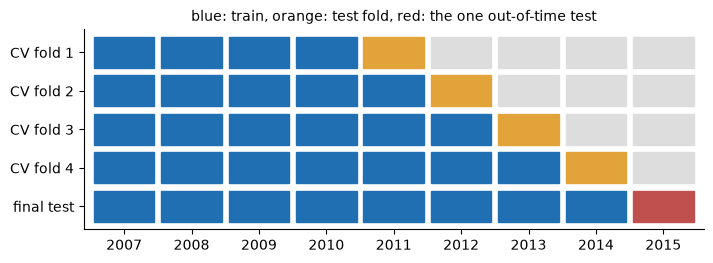

development loans: 337,996 (bad rate 13.2%), out-of-time 2015: 283,026 (bad rate 14.9%)


In [8]:
fig, ax = plt.subplots(figsize=(8, 2.6))
years = list(range(2007, 2016))
for row, (test_year, tr, te) in enumerate(target.time_folds(dev)):
    for y in years:
        color = "#1f6fb2" if y < test_year else "#e3a33b" if y == test_year else "#dddddd"
        ax.add_patch(plt.Rectangle((y - 0.45, row - 0.4), 0.9, 0.8, color=color))
ax.add_patch(plt.Rectangle((2015 - 0.45, 4 - 0.4), 0.9, 0.8, color="#c0504d"))
for y in years[:-1]:
    ax.add_patch(plt.Rectangle((y - 0.45, 4 - 0.4), 0.9, 0.8, color="#1f6fb2"))
ax.set(xlim=(2006.4, 2015.6), ylim=(-0.6, 4.6), xticks=years, yticks=range(5),
       yticklabels=["CV fold 1", "CV fold 2", "CV fold 3", "CV fold 4", "final test"])
ax.invert_yaxis()
ax.set_title("blue: train, orange: test fold, red: the one out-of-time test", fontsize=10)
plt.show()
print(f"development loans: {len(dev):,} (bad rate {dev['bad'].mean():.1%}), out-of-time 2015: {len(oot):,} (bad rate {oot['bad'].mean():.1%})")

## 4. Binning: Weight of Evidence (WoE) and Information Value (IV)

A scorecard does not use FICO = 703 directly. It cuts each characteristic into a few **bins** (for example FICO 700–709)
and asks: how risky is this bin compared to everyone?

**Weight of Evidence** of a bin:

$$\text{WoE} = \ln\left(\frac{\text{share of all goods that fall in the bin}}{\text{share of all bads that fall in the bin}}\right)$$

Positive WoE = safer than average, negative = riskier, 0 = average. Missing values get their own bin.

**Information Value** sums up how well the whole characteristic separates goods from bads:

$$\text{IV} = \sum_{\text{bins}} (\text{share of goods} - \text{share of bads}) \times \text{WoE}$$

Rules of thumb: below 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong.

Why bins? They handle outliers and missing values naturally, they can follow a business rule (a higher FICO score must never look
riskier), and they make the final model a simple table anyone can read.

The cut points come from `optbinning`, with the trend forced where it is a business rule and at least 5 % of loans per bin.
Here is FICO on the development years:

In [9]:
X_dev, y_dev = features.build(dev), dev["bad"].to_numpy()
fico = binning.fit_one("fico", X_dev["fico"], y_dev)
fico_table = pd.DataFrame({"bin": binning.labels(fico), "loans": fico["n"], "bad rate": fico["bad_rate"], "WoE": fico["woe"]})
fico_table = fico_table[fico_table["loans"] > 0]
print(f"IV of FICO: {fico['iv']:.3f}")
fico_table

IV of FICO: 0.141


,bin,loans,bad rate,WoE
0,< 664.5,28709,0.1884,-0.4265
1,664.5 to < 674.5,57375,0.1739,-0.3288
2,674.5 to < 689.5,76338,0.1526,-0.1726
3,689.5 to < 699.5,43603,0.1314,0.0014
4,699.5 to < 709.5,35346,0.1158,0.1455
5,709.5 to < 729.5,46548,0.0962,0.3531
6,729.5 to < 759.5,31137,0.0721,0.6678
7,>= 759.5,18940,0.0471,1.1202


Now the same WoE and IV **by hand** from the counts, to see the formula at work:

In [10]:
codes = binning.bin_codes(fico, X_dev["fico"])
by_bin = pd.DataFrame({"bin": codes, "bad": y_dev}).groupby("bin")["bad"].agg(n="size", bads="sum")
by_bin["goods"] = by_bin["n"] - by_bin["bads"]
by_bin["share_goods"] = by_bin["goods"] / by_bin["goods"].sum()
by_bin["share_bads"] = by_bin["bads"] / by_bin["bads"].sum()
by_bin["woe_by_hand"] = np.log(by_bin["share_goods"] / by_bin["share_bads"])
iv_by_hand = ((by_bin["share_goods"] - by_bin["share_bads"]) * by_bin["woe_by_hand"]).sum()
print(f"IV by hand: {iv_by_hand:.4f}   (library: {fico['iv']:.4f})")
by_bin[["n", "bads", "share_goods", "share_bads", "woe_by_hand"]]

IV by hand: 0.1414   (library: 0.1414)


,n,bads,share_goods,share_bads,woe_by_hand
bin,,,,,
0,28709,5408,0.0794,0.1216,-0.4265
1,57375,9977,0.1615,0.2243,-0.3288
2,76338,11648,0.2204,0.2619,-0.1726
3,43603,5730,0.1290,0.1288,0.0014
4,35346,4094,0.1065,0.0921,0.1455
5,46548,4478,0.1433,0.1007,0.3531
6,31137,2245,0.0984,0.0505,0.6678
7,18940,892,0.0615,0.0201,1.1202


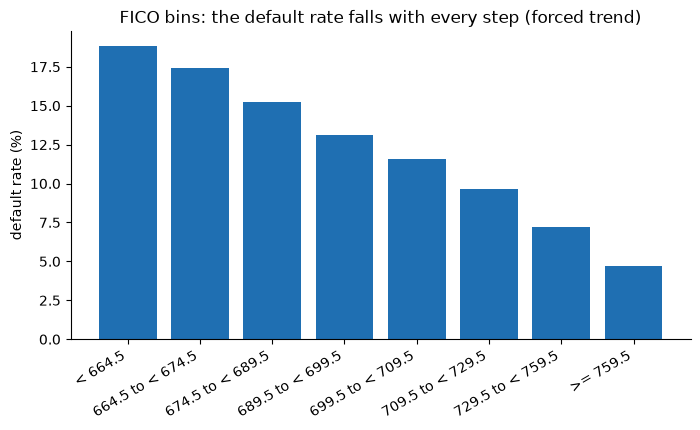

In [11]:
fig, ax = plt.subplots()
ax.bar(fico_table["bin"], fico_table["bad rate"] * 100, color="#1f6fb2")
ax.set(ylabel="default rate (%)", title="FICO bins: the default rate falls with every step (forced trend)")
plt.xticks(rotation=30, ha="right")
plt.show()

Every candidate characteristic gets the same treatment. The IVs show how little separates the applicants: the strongest,
FICO, is only "medium" (0.14). The reason is that these are **approved** loans only: Lending Club had already turned
the riskiest people away, so the remaining differences are small.

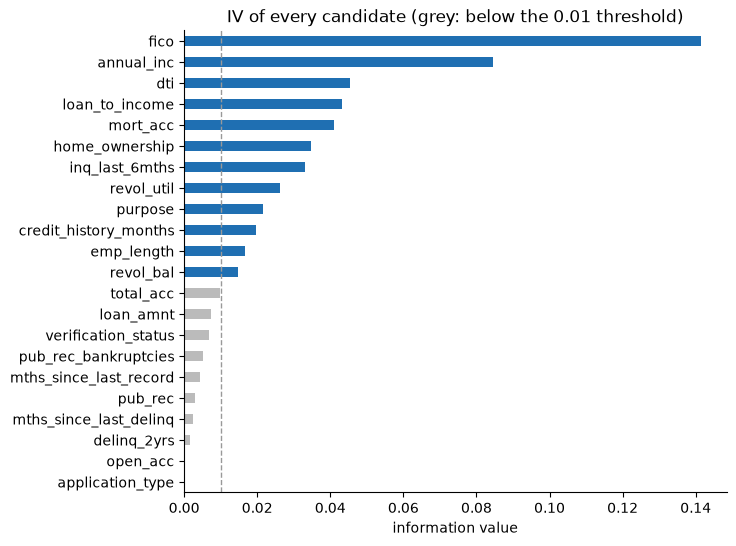

In [12]:
specs = binning.fit_all(X_dev, y_dev)
iv = pd.Series({name: s["iv"] for name, s in specs.items()}).sort_values(ascending=False)
ax = iv.plot.barh(figsize=(7, 6), color=["#1f6fb2" if v >= scorecard.IV_MIN else "#bbbbbb" for v in iv])
ax.invert_yaxis()
ax.axvline(scorecard.IV_MIN, color="#999999", ls="--", lw=1)
ax.set(xlabel="information value", title="IV of every candidate (grey: below the 0.01 threshold)")
plt.show()

## 5. From bins to a points scorecard

**Step 1, choose characteristics** (`scorecard.select`): strongest IV first, skip one whose WoE values correlate above 0.6
with one already chosen (they would tell the same story twice), and leave out income verification (Lending Club verified mostly
people it already found risky, so it carries Lending Club's own judgement and is not a fair reason to decline someone).

**Step 2, logistic regression on the WoE values:**

$$\ln\frac{P(\text{bad})}{P(\text{good})} = b_0 + b_1\,\text{WoE}_1 + \dots + b_k\,\text{WoE}_k$$

With WoE inputs every coefficient must be **negative** (a safer bin must lower the default odds). A positive one means two
characteristics overlap; the code drops it and refits.

**Step 3, how many characteristics?** The time cross-validation tried up to 6, 9 and 12. The mean Gini (explained in section 7)
of 9 and 12 is the same within noise, so the smaller scorecard wins. The saved scorecard (`models/scorecard.json`) keeps that result:

In [13]:
card = applicant.load_card()
cv = pd.DataFrame(card["cv"]).pivot(index="test_year", columns="max_features", values="gini")
cv.columns = [f"up to {c}" for c in cv.columns]
cv.loc["mean"] = cv.mean()
cv

,up to 6,up to 9,up to 12
test_year,,,
2011,0.3233,0.3423,0.3409
2012,0.2775,0.2923,0.2929
2013,0.2764,0.2732,0.2768
2014,0.2750,0.2919,0.2961
mean,0.2881,0.2999,0.3017


Refitting on all development years with up to 9 characteristics reproduces the saved scorecard exactly:

In [14]:
Xw = binning.transform(specs, X_dev)
refit = scorecard.fit(specs, Xw, y_dev, 9)
same = [c["points"] for c in refit["characteristics"]] == [c["points"] for c in card["characteristics"]]
print("refit gives the same points as models/scorecard.json:", same)
chosen = [c["name"] for c in card["characteristics"]]
pd.DataFrame({"characteristic": chosen,
              "coefficient": [round(c["coef"], 3) for c in card["characteristics"]],
              "IV": [c["iv"] for c in card["characteristics"]],
              "VIF": scorecard.vif(Xw[chosen]).to_numpy()})

refit gives the same points as models/scorecard.json: True


,characteristic,coefficient,IV,VIF
0,fico,-0.8360,0.1414,1.4100
1,annual_inc,-0.5120,0.0844,1.3800
2,dti,-0.5720,0.0453,1.1100
3,loan_to_income,-0.7510,0.0432,1.2000
4,mort_acc,-0.3070,0.0409,1.6400
5,home_ownership,-0.3440,0.0348,1.5800
6,inq_last_6mths,-1.0920,0.0332,1.0400
7,revol_util,-0.2010,0.0262,1.4200
8,purpose,-0.9860,0.0217,1.0100


All coefficients are negative and every VIF (how much a characteristic is explained by the others) is below 2, so there is
no problematic overlap.

**Step 4, turn the regression into points.** Banks scale scores so they are easy to read:
600 points mean odds of 50 goods to 1 bad, and every 20 points double the odds (PDO = "points to double the odds").

$$\text{factor} = \frac{20}{\ln 2} = 28.85, \qquad \text{offset} = 600 - \text{factor}\cdot\ln 50 = 487.1$$

$$\text{score} = \text{offset} + \text{factor}\cdot\ln(\text{odds of good}) = \text{offset} - \text{factor}\,(b_0 + \textstyle\sum b_i\,\text{WoE}_i)$$

Splitting that sum by characteristic gives the points of each bin (the intercept is shared out equally):

$$\text{points}_{ij} = -\text{factor}\cdot b_i\cdot\text{WoE}_{ij} + \frac{\text{offset} - \text{factor}\cdot b_0}{k}$$

In [15]:
print(f"factor = {scorecard.FACTOR:.2f}, offset = {scorecard.OFFSET:.1f}")
c = card["characteristics"][0]  # FICO
base = (scorecard.OFFSET - scorecard.FACTOR * card["intercept"]) / len(card["characteristics"])
by_hand = [round(-scorecard.FACTOR * c["coef"] * w + base) for w in c["woe"]]
pd.DataFrame({"FICO bin": c["labels"], "WoE": c["woe"], "points by hand": by_hand, "points in the scorecard": c["points"]})

factor = 28.85, offset = 487.1


,FICO bin,WoE,points by hand,points in the scorecard
0,664 or less,-0.4265,50,50
1,665 to 674,-0.3288,52,52
2,675 to 689,-0.1726,56,56
3,690 to 699,0.0014,60,60
4,700 to 709,0.1455,64,64
5,710 to 729,0.3531,69,69
6,730 to 759,0.6678,76,76
7,760 or more,1.1202,87,87
8,not given,-0.4265,50,50


The full scorecard: one table, nine characteristics. The score is the sum of the points of the applicant's bins.

In [16]:
table = scorecard.table(card)
table[["characteristic", "bin", "loans", "bad_rate", "points"]]

,characteristic,bin,loans,bad_rate,points
0,FICO score,664 or less,28709,0.1884,50
1,FICO score,665 to 674,57375,0.1739,52
2,FICO score,675 to 689,76338,0.1526,56
3,FICO score,690 to 699,43603,0.1314,60
4,FICO score,700 to 709,35346,0.1158,64
...,...,...,...,...,...
61,loan purpose,"car, paying off credit cards or major purchase",91609,0.1104,66
62,loan purpose,home improvement,18668,0.1153,64
63,loan purpose,debt consolidation,190806,0.1365,59
64,loan purpose,"medical, small business or other",36913,0.1670,52


## 6. Reasons for every decision

Because the score is a sum of points, the reasons are easy to find: for each characteristic, how many points did the applicant lose
compared with the best bin? The three biggest losses are the reasons. This matters legally in the EU: after the CJEU's SCHUFA ruling
(C-634/21, 2023), automated credit scores fall under GDPR Art. 22, and the EU AI Act counts credit scoring as high-risk.

A real applicant from 2015 (a year the scorecard never saw):

In [17]:
X_oot = features.build(oot)
s_oot = scorecard.score(card, X_oot)
i = s_oot.idxmin()
row = X_oot.loc[[i]]
pts = scorecard.points(card, row).iloc[0]
pd.DataFrame({"answer": [row[n].iloc[0] for n in chosen],
              "points": pts.values,
              "best possible": [max(c["points"]) for c in card["characteristics"]]}, index=chosen)

,answer,points,best possible
fico,662.0000,50,87
annual_inc,"5,400.0000",53,67
dti,34.8900,54,65
loan_to_income,0.3194,55,66
mort_acc,0.0000,58,63
home_ownership,RENT,58,62
inq_last_6mths,3.0000,48,65
revol_util,24.9000,62,62
purpose,other,52,66


In [18]:
print(f"score {int(pts.sum())}, PD {scorecard.pd_from_score(pts.sum()):.1%}, actually defaulted: {bool(oot.loc[i, 'bad'])}")
for r in scorecard.reasons(card, row)[0]:
    print(f"  - {r['text']}  (-{r['points_lost']} points)")

score 490, PD 47.5%, actually defaulted: False
  - FICO score: 664 or less  (-37 points)
  - credit inquiries in the last 6 months: 3 or more  (-17 points)
  - annual income: below $27,300  (-14 points)


## 7. The out-of-time test: 2015

Two ranking measures, both computed on loans the model never saw:

- **Gini** = 2 × AUC − 1. AUC is the chance that a randomly picked defaulter got a worse score than a randomly picked good payer.
  0 = random, 1 = perfect. In consumer credit with application data only, 0.3–0.5 is typical.
- **KS** = the largest gap between the cumulative score distributions of bads and goods.

By hand on 2015 (AUC via ranks, the Mann-Whitney way), next to the library:

In [19]:
risk = -s_oot.to_numpy()
y_oot = oot["bad"].to_numpy()
ranks = pd.Series(risk).rank().to_numpy()
n_bad, n_good = y_oot.sum(), len(y_oot) - y_oot.sum()
auc_by_hand = (ranks[y_oot == 1].sum() - n_bad * (n_bad + 1) / 2) / (n_bad * n_good)
print(f"AUC by hand {auc_by_hand:.4f} -> Gini {2 * auc_by_hand - 1:.4f}   (library Gini {validation.gini(y_oot, risk):.4f}, KS {validation.ks(y_oot, risk):.4f})")

AUC by hand 0.6514 -> Gini 0.3029   (library Gini 0.3029, KS 0.2177)


**The comparison.** The benchmark is Lending Club's own sub-grade (A1 … G5), which was built with the full credit report.
The challenger is LightGBM on the same 22 application characteristics, with monotone constraints (a higher FICO score can never
raise its default estimate). Its number of trees is chosen by early stopping on 2014, then it is refit on 2007–2014.

In [20]:
earlier, last = (dev["year"] < 2014).to_numpy(), (dev["year"] == 2014).to_numpy()
rounds = challenger.best_rounds(X_dev[earlier], y_dev[earlier], X_dev[last], y_dev[last])
model = challenger.fit(X_dev, y_dev, rounds)
pd_challenger = challenger.predict(model, X_oot)
grade_risk = validation.subgrade_rank(oot["sub_grade"]).to_numpy()
results = pd.DataFrame({
    "Lending Club sub-grade (benchmark)": validation.summary(y_oot, grade_risk),
    "LightGBM challenger": validation.summary(y_oot, pd_challenger),
    "Scorecard": validation.summary(y_oot, risk),
}).T
print(f"challenger: {rounds} trees")
results

challenger: 177 trees


,gini,ks
Lending Club sub-grade (benchmark),0.3573,0.2619
LightGBM challenger,0.3429,0.2489
Scorecard,0.3029,0.2177


Is the challenger's lead real or luck? A **bootstrap**: resample the 2015 loans with replacement many times, recompute the Gini
difference each time, and look at the middle 95 % of the results (50 resamples here to keep the notebook fast; the report uses 200).

In [21]:
diff = validation.bootstrap_diff(y_oot, pd_challenger, risk, reps=50)
print(f"challenger minus scorecard: {diff['diff']:+.3f}  (95 % interval {diff['low']:+.3f} to {diff['high']:+.3f}): clearly not luck")

challenger minus scorecard: +0.040  (95 % interval +0.038 to +0.042): clearly not luck


And by year: the scorecard and the challenger beat Lending Club's grade until 2012, then the grade improved every year
(Lending Club kept refining it with richer data), while our models only see 22 application fields.

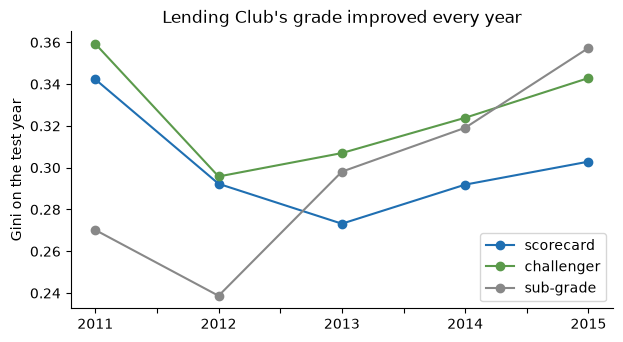

,scorecard,challenger,sub-grade
2011,0.3423,0.3593,0.2702
2012,0.2923,0.2958,0.2387
2013,0.2732,0.3070,0.2981
2014,0.2919,0.3239,0.3191
2015,0.3029,0.3429,0.3573


In [22]:
by_year = pd.DataFrame(json.loads((config.ROOT / "models" / "validation.json").read_text())["gini_by_year"]).T
ax = by_year.plot(marker="o", figsize=(7, 3.6), color=["#1f6fb2", "#5b9a4b", "#888888"])
ax.set(ylabel="Gini on the test year", title="Lending Club's grade improved every year")
plt.show()
by_year

**Champion or challenger?** The challenger ranks clearly better, but the scorecard explains every decision with a table.
A bank keeps the explainable champion until the challenger is worth the extra explanation work (section 9 puts a money value on it).

The SHAP values show what drives the challenger. `open_acc` matters there although its IV is almost zero: the challenger finds
interactions an additive scorecard cannot represent.

In [23]:
challenger.importance(model, X_oot, sample=10000).round(4).to_frame("mean |SHAP|").head(10)

,mean |SHAP|
fico,0.3094
annual_inc,0.1425
inq_last_6mths,0.1337
dti,0.1291
loan_to_income,0.1145
purpose,0.0872
revol_bal,0.0765
open_acc,0.0735
home_ownership,0.0688
revol_util,0.0621


## 8. Calibration: are the predicted default rates right?

Ranking well is not enough: a bank also needs the **level** to be right, because it prices and provisions with the PD.
Check: sort 2015 loans into 10 equal groups by predicted PD and compare the average prediction with the observed default rate.

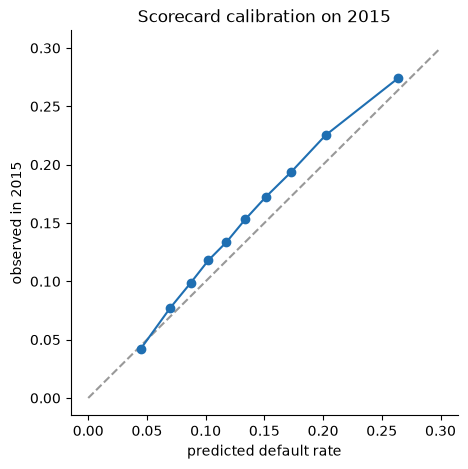

mean predicted 13.5% vs observed 14.9%


In [24]:
pd_card = scorecard.pd_from_score(s_oot)
cal = validation.calibration(y_oot, pd_card)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 0.3], [0, 0.3], ls="--", color="#999999")
ax.plot(cal["predicted"], cal["observed"], marker="o", color="#1f6fb2")
ax.set(xlabel="predicted default rate", ylabel="observed in 2015", title="Scorecard calibration on 2015")
plt.show()
print(f"mean predicted {pd_card.mean():.1%} vs observed {y_oot.mean():.1%}")

Every point sits above the diagonal: the model predicts too few defaults, in every band. The ranking holds, but 2015 was a riskier
year than any development year. This is exactly what monitoring must catch (section 11).

## 9. From score to decision: what is it worth?

The economics come from 2007–2014: a defaulted loan loses about 36.5 % of the amount lent (after what was paid before the default and
recoveries); a repaid loan earns its interest. The rule approves when the expected profit is positive:

$$\text{expected profit} = (1-\text{PD})\times\text{gain if repaid} - \text{PD}\times\text{loss rate}\times\text{amount}$$

In [25]:
lgd = strategy.loss_rate(dev)
approve = strategy.expected_profit(oot, pd_card, lgd) > 0
pd.DataFrame({
    "approve everyone (what was funded)": strategy.outcome(oot, np.ones(len(oot), dtype=bool)),
    "scorecard rule": strategy.outcome(oot, approve),
}).T

,approval_rate,bad_rate,profit_musd,declined_loans,declined_bad_rate
approve everyone (what was funded),1.0000,0.1489,198.8200,0.0000,NaN
scorecard rule,0.9968,0.1488,198.4700,913.0000,0.1818


The surprise: once Lending Club had approved **and priced** a loan, declining it almost never paid. Riskier loans paid higher interest,
and the price covered the risk. So the rule declines well under 1 %.

Where the ranking is worth money is **selection**: an investor who can fund only half of the loans and picks the safest.

In [26]:
rankings = {"Lending Club sub-grade": grade_risk, "Scorecard": pd_card, "LightGBM challenger": pd_challenger}
pd.DataFrame({name: strategy.pick_share(oot, r, 0.5) for name, r in rankings.items()}).T

,profit_musd,lent_musd,return_on_lent,bad_rate
Lending Club sub-grade,117.0000,"1,920.4000",0.0609,0.0825
Scorecard,124.7800,"1,984.1000",0.0629,0.0940
LightGBM challenger,129.1500,"1,955.4000",0.0660,0.0862


Picking by Lending Club's grade picks the cheapest loans, which also earn the least interest. The models find people who are safer than
their price suggests, so they earn more per dollar lent, although their default rate is a little higher.

## 10. Reject bias: who the model never saw

The model learned only from approved loans. Lending Club turned down millions of applications, and their file has a risk score:

,accepted,rejected
applications,"887,440.0000","6,309,512.0000"
risk score known,1.0000,0.5800
median risk score,692.0000,641.0000
share below 660,0.0010,0.6280
median DTI (%),17.7000,17.1000
share DTI above 40 %,0.0000,0.1700
median amount,"13,000.0000","10,000.0000"


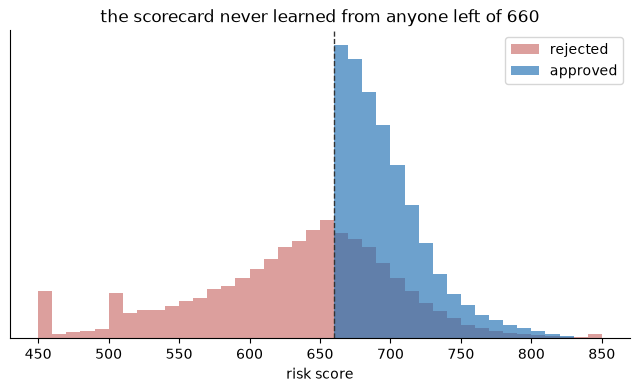

In [27]:
if REAL:
    rejected = rejects.load()
    accepted = loans[loans["issue_d"].dt.year <= 2015]
    display(rejects.compare(accepted, rejected))
    acc_fico = (accepted["fico_range_low"] + accepted["fico_range_high"]) / 2
    fig, ax = plt.subplots()
    bins = np.arange(450, 851, 10)
    ax.hist(rejected["risk_score"].dropna().clip(450, 850), bins=bins, density=True, alpha=.55, color="#c0504d", label="rejected")
    ax.hist(acc_fico.clip(450, 850), bins=bins, density=True, alpha=.65, color="#1f6fb2", label="approved")
    ax.axvline(660, color="#333333", ls="--", lw=1)
    ax.set(xlabel="risk score", yticks=[], title="the scorecard never learned from anyone left of 660")
    ax.legend()
    plt.show()
else:
    print("needs the real rejected-applications file")

63 % of rejected applicants scored below 660, where there is almost no approved loan. The scorecard's lowest FICO bin ("664 or less")
was learned from people around 660–664, so its PD for someone at 580 is a guess, and almost certainly too low.
Section 12 shows how the lending rules handle this.

## 11. Monitoring after go-live

The validated scorecard goes live in January 2015 and scores every application up to 2018. Two kinds of checks:

**Inputs, from day one: PSI** (population stability index). Compare the share of applicants per score band now with the development
sample:

$$\text{PSI} = \sum_{\text{bands}} (\text{share now} - \text{share then}) \times \ln\frac{\text{share now}}{\text{share then}}$$

Below 0.10 green, 0.10–0.25 amber, above 0.25 red. Applied to one characteristic it is called CSI. By hand for one quarter:

In [28]:
s_dev = scorecard.score(card, X_dev).to_numpy()
edges = monitor.score_bins(s_dev)
then = monitor.shares(np.digitize(s_dev, edges), len(edges) + 1)
live = loans[(loans["term"] == 36) & (loans["issue_d"] >= "2018-07-01") & (loans["issue_d"] < "2018-10-01")]
s_live = scorecard.score(card, features.build(live)).to_numpy()
now = monitor.shares(np.digitize(s_live, edges), len(edges) + 1)
psi_by_hand = np.sum((now - then) * np.log(now / then))
print(f"score PSI 2018 Q3 by hand: {psi_by_hand:.3f}   (library: {monitor.psi(then, now):.3f}) -> {monitor.light(psi_by_hand)}")
pd.DataFrame({"share 2007-2014": then, "share 2018 Q3": now}).round(3).T

score PSI 2018 Q3 by hand: 0.094   (library: 0.094) -> green


,0,1,2,3,4,5,6,7,8,9
share 2007-2014,0.0900,0.1040,0.1020,0.0920,0.0970,0.0940,0.1060,0.1050,0.1060,0.1030
share 2018 Q3,0.0440,0.0690,0.0790,0.0780,0.0900,0.0950,0.1160,0.1300,0.1410,0.1580


**Outcomes, as they arrive.** A full 36-month outcome takes over 3 years, far too slow. The early warning is the share of loans that
went bad in their first 12 months, observed vs what the model expected (from a 12-month PD fitted on the development years only).
It can be counted about 15 months after the loans are issued. The full table comes from `make monitor`:

In [29]:
mon = pd.DataFrame(json.loads((config.ROOT / "models" / "monitoring.json").read_text())["quarters"]).set_index("quarter")
mon[["applications", "score PSI", "early bad observed", "early bad expected", "observed / expected", "known from"]]

,applications,score PSI,early bad observed,early bad expected,observed / expected,known from
quarter,,,,,,
2015Q1,56569,0.0060,0.0494,0.0480,1.0300,2016-06
2015Q2,64222,0.0015,0.0531,0.0471,1.1300,2016-09
2015Q3,73572,0.0008,0.0523,0.0455,1.1500,2016-12
2015Q4,88810,0.0020,0.0547,0.0451,1.2100,2017-03
2016Q1,96120,0.0029,0.0596,0.0449,1.3300,2017-06
2016Q2,74537,0.0020,0.0643,0.0450,1.4300,2017-09
2016Q3,73898,0.0051,0.0673,0.0452,1.4900,2017-12
2016Q4,78940,0.0060,0.0623,0.0445,1.4000,2018-03
2017Q1,72410,0.0157,0.0554,0.0430,1.2900,2018-06


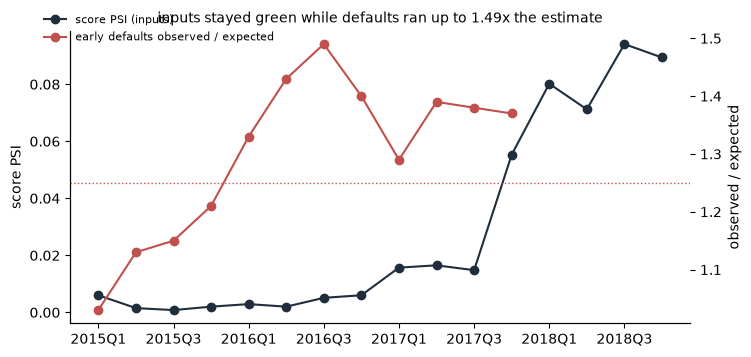

In [30]:
fig, ax1 = plt.subplots(figsize=(8, 3.8))
ax1.plot(mon.index, mon["score PSI"], marker="o", color="#1f2d3d", label="score PSI (inputs)")
ax1.set_ylabel("score PSI")
ax2 = ax1.twinx()
ax2.plot(mon.index, mon["observed / expected"], marker="o", color="#c0504d", label="early defaults observed / expected")
ax2.axhline(1.25, color="#c0504d", ls=":", lw=1)
ax2.set_ylabel("observed / expected")
ax1.set_xticks(mon.index[::2])
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.95), frameon=False, fontsize=8)
ax1.set_title("inputs stayed green while defaults ran up to 1.49x the estimate", fontsize=10)
plt.show()

**The lesson:** in 2015–2016 the applicants looked unchanged (PSI ≤ 0.006), yet early defaults rose to 1.49 times the estimate,
a red light visible from June 2017. Input stability is not model health. The action would be to recalibrate the PD level
(the ranking still held) and later rebuild on recent loans.

## 12. Using it: lending rules, then the score

Testing the public page showed a real problem: a 40,000 loan on a 5,000 income was approved. The scorecard's last bins are open-ended
("33 % or more of income"), and Lending Club never approved such a loan, so the model had no evidence and scored it like the worst case
it knew. Real lenders run **lending rules** before any score. Here each limit sits at the edge of the approved loans:

In [31]:
rules_table, rules_summary = policy.evidence(loans)
print(rules_summary)
rules_table

{'loans': 337996, 'breaking any rule': 3585, 'share': 0.0106, 'default rate of those': 0.247, 'default rate of the rest': 0.13}


,rule (decline if),approved loans breaking it,share,their default rate
0,FICO score below 660,489,0.0014,0.3090
1,"annual income below $10,000",287,0.0008,0.1570
2,"loan above $35,000",0,0.0000,NaN
3,loan above 50 % of annual income,260,0.0008,0.2270
4,debt-to-income above 40 % before this loan,0,0.0000,NaN
5,debt-to-income above 50 % including this loan'...,1576,0.0047,0.2610
6,more than 7 credit inquiries in 6 months,248,0.0007,0.3630
7,revolving balances above the credit limit (ove...,833,0.0025,0.1960


The rules would have declined 1 % of the loans Lending Club approved, and those defaulted far more often than the rest: they catch real
risk, not random loans.

Finally, scoring one application exactly as the API (`POST /score`) and the public page do: rules first, then points, PD,
the interest rate that covers the expected loss, the decision and the reasons.

In [32]:
def show(application):
    r = applicant.score_application(application)
    print(f"score {r['score']}, PD {r['pd']:.1%}, decision: {r['decision'].upper()} ({r['decision_rule']})")
    for b in r["rules_broken"]:
        print("  rule broken:", b["text"])
    if not r["rules_broken"]:
        if r["decision"] == "approve":
            print(f"  rate that covers the expected loss: {r['break_even_rate']:.1%}")
        for x in r["reasons"]:
            print(f"  reason: {x['text']} (-{x['points_lost']})")
    print()

typical = {"fico_score": 695, "inquiries_last_6_months": 1, "revolving_utilisation": 55, "mortgage_accounts": 1,
           "annual_income": 60000, "debt_to_income": 18, "home_ownership": "RENT", "loan_amount": 12000,
           "purpose": "debt_consolidation"}
show(typical)
show(typical | {"annual_income": 5000, "loan_amount": 40000})  # the case a tester found
show(typical | {"fico_score": 662, "inquiries_last_6_months": 3, "revolving_utilisation": 92, "mortgage_accounts": 0,
                "annual_income": 26000, "debt_to_income": 25, "loan_amount": 10000, "purpose": "small_business"})

score 536, PD 15.5%, decision: APPROVE (rate covers the expected loss)
  rate that covers the expected loss: 4.9%
  reason: FICO score: 690 to 699 (-27)
  reason: annual income: $50,400 to $62,000 (-7)
  reason: credit inquiries in the last 6 months: 1 (-7)

score 520, PD 24.2%, decision: DECLINE (lending rule)
  rule broken: annual income below $10,000
  rule broken: loan above $35,000
  rule broken: loan above 50 % of annual income
  rule broken: debt-to-income above 50 % including this loan's payment

score 487, PD 50.1%, decision: DECLINE (pd above policy limit)
  reason: FICO score: 664 or less (-37)
  reason: credit inquiries in the last 6 months: 3 or more (-17)
  reason: annual income: below $27,300 (-14)



## Summary: what to remember

1. **Leakage first.** Half the columns are post-loan; one alone gives Gini 1.0. Only application-time data may enter the model.
2. **Split by time.** Develop on 2007–2014 with time cross-validation, test once on 2015.
3. **WoE bins + logistic regression + points** = a model that is a readable table, with a reason for every decision.
4. **Honest results.** Scorecard Gini 0.30, LightGBM challenger 0.34, Lending Club's grade 0.36. The grade improved every year with
   richer data; with application data alone the challenger comes within 0.014.
5. **Calibration drifts.** 2015 was riskier than any development year: the ranking held, the level did not.
6. **Money.** At the lender's prices declining more barely pays; the ranking pays in selection (6.29 % vs 6.09 % return when funding half).
7. **Reject bias.** The model never saw rejected applicants, so lending rules at the edge of the data decide those cases.
8. **Monitoring.** Stable inputs hid a 1.49× rise in early defaults: watch outcomes, not only inputs.

Not for real lending decisions: US data, 2007–2018, one lender, approved loans only.